# Stage 1 Data Analysis

### Imports

In [31]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory
from scipy.signal import savgol_filter


### Check on Topics

In [32]:
with open("data-real/stage-1-test-left-1/stage-1-test-left-1.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   33
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/tf                                      tf2_msgs/msg/TFMessage                   1179
/tf_static                               tf2_msgs/msg/TFMessage                   1
/vicon/athena/athena                     geometry_msgs/msg/PoseStamped            1177
/sensors/imu/raw                         sensor_msgs/msg/Imu                      353
/sensors/servo_position_command          std_msgs/msg/Float64                     48
/commands/motor/speed                    std_msgs/msg/Float64                     48
/commands/servo/position                 std_msgs/msg/Float64                     48
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 47


### Check on Vicon Datapoints

stage-1-test-left-3: 1384 Msg (0 deleted)
stage-1-test-straight-3-3: 2028 Msg (10 deleted)
stage-1-test-right-2: 1453 Msg (1 deleted)
stage-1-test-straight-2-1: 3333 Msg (0 deleted)
stage-1-test-straight-2-3: 2180 Msg (10 deleted)
stage-1-test-right-3-2: 1372 Msg (422 deleted)
stage-1-test-left-3-1: 2330 Msg (0 deleted)
stage-1-test-left-3-3: 1416 Msg (0 deleted)
stage-1-test-straight-1-2: 1521 Msg (215 deleted)
stage-1-test-right-3-3: 1023 Msg (544 deleted)
stage-1-test-right-3: 1546 Msg (0 deleted)
stage-1-test-left-2: 1414 Msg (0 deleted)
stage-1-test-straight-1-1: 1632 Msg (0 deleted)
stage-1-test-straight-2-2: 3373 Msg (47 deleted)
stage-1-test-straight-3-2: 2023 Msg (0 deleted)
stage-1-test-left-3-2: 1135 Msg (386 deleted)
stage-1-test-straight-1-3: 1567 Msg (343 deleted)
stage-1-test-right-3-1: 1068 Msg (434 deleted)
stage-1-test-right-1: 1425 Msg (0 deleted)
stage-1-test-straight-3-1: 2283 Msg (0 deleted)
stage-1-test-left-1: 1177 Msg (0 deleted)


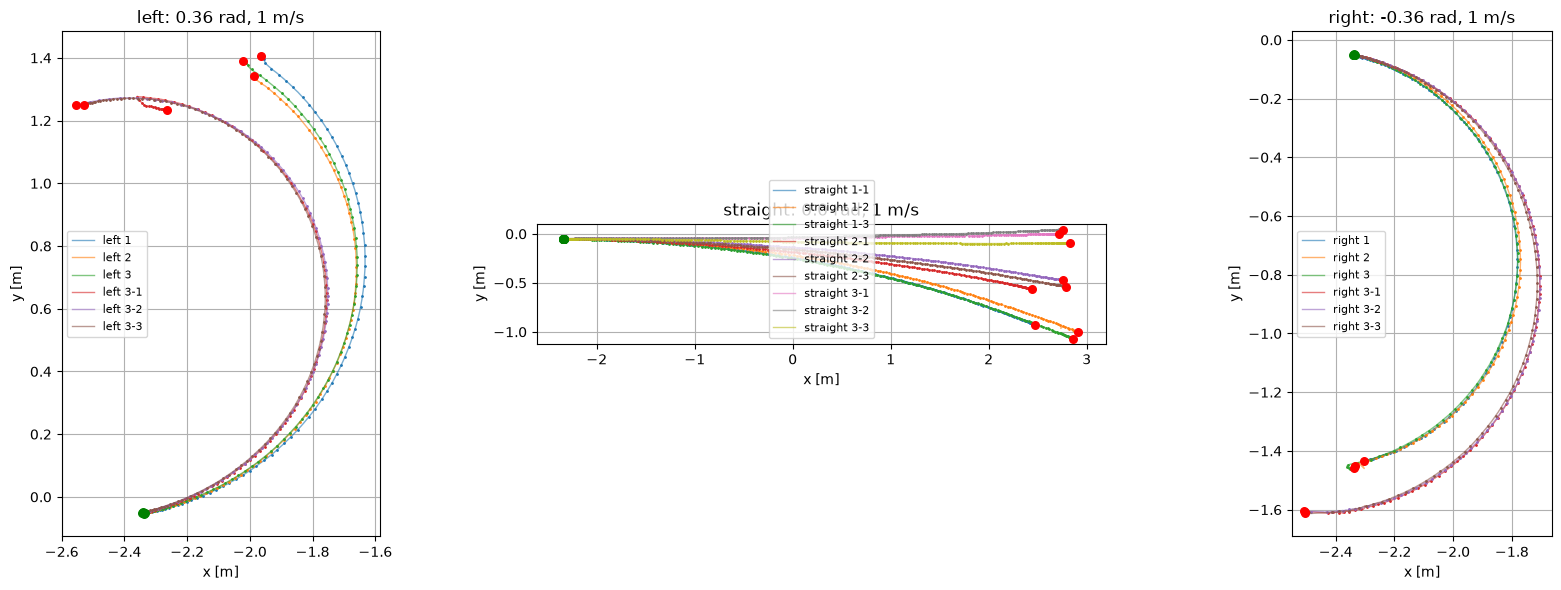

In [33]:
rootdir = "data-real/"
n = 5              
max_speed = 5.0    
groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}

def load_vicon(path, topic="/vicon/athena/athena"):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for schema, channel, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p = msg.pose.position
            q = msg.pose.orientation
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,  # Vicon-Zeit
                "t_log": message.log_time / 1e9,                               # Aufnahmezeit
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
            })
    return pd.DataFrame(rows).sort_values("t").reset_index(drop=True)

def remove_jumps(df, max_speed=5.0, tol=0.01, origin_eps=1e-3):
    if df.empty:
        return df

    # remove tracking errors by setting them to the origin
    at_origin = (df["px"].abs() < origin_eps) & (df["py"].abs() < origin_eps) & (df["pz"].abs() < origin_eps)
    df = df[~at_origin].reset_index(drop=True)
    if df.empty:
        return df

    # remove outliers via speed
    t = df["t"].to_numpy()
    x = df["px"].to_numpy()
    y = df["py"].to_numpy()

    keep = np.zeros(len(df), dtype=bool)
    keep[0] = True
    last = 0
    for i in range(1, len(df)):
        dist = np.hypot(x[i] - x[last], y[i] - y[last])
        if dist <= max_speed * (t[i] - t[last]) + tol:
            keep[i] = True
            last = i
    return df[keep].reset_index(drop=True)

def cut_at_gap(df, max_gap=0.2):
    if df.empty:
        return df
    dt = df["t"].diff().to_numpy()
    gaps = np.where(dt > max_gap)[0]
    if len(gaps):
        df = df.iloc[:gaps[0]]
    return df.reset_index(drop=True)

dfs = {g: {} for g in groups}
for subdir, dirs, files in os.walk(rootdir):
    for file in files:
        if not file.endswith(".mcap"):
            continue
        name = os.path.splitext(file)[0]
        
        m = re.search(r"(left|straight|right)-(\d+(?:-\d+)*)$", name)
        if not m:
            continue
        group, run = m.group(1), m.group(2)     

        df = load_vicon(os.path.join(subdir, file))
        n_before = len(df)
        df = remove_jumps(df, max_speed=max_speed)
        df = cut_at_gap(df, max_gap=0.2)          # <-- neu
        print(f"{name}: {len(df)} Msg ({n_before - len(df)} deleted)")

        if not df.empty:
            dfs[group][run] = df

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.tab10.colors

for ax, group in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[group])):
        df = dfs[group][run]
        c = colors[i % len(colors)]
        ax.plot(df["px"], df["py"], "-", color=c, linewidth=1, alpha=0.6, label=f"{group} {run}")
        ax.plot(df["px"][::n], df["py"][::n], "o", color=c, markersize=1)
        ax.scatter(df["px"].iloc[0], df["py"].iloc[0], color="green", s=30, zorder=3)
        ax.scatter(df["px"].iloc[-1], df["py"].iloc[-1], color="red", s=30, zorder=3)

    ax.set_title(titles[group])
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

##### Check on real Speed

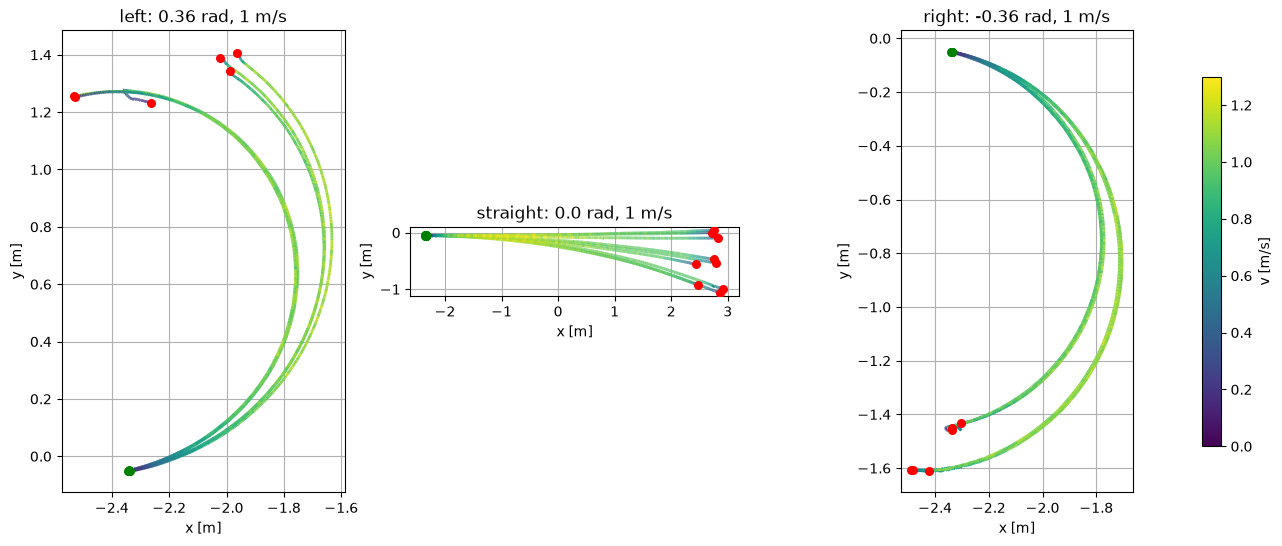

In [34]:
from matplotlib.collections import LineCollection

k = 5
vmax_plot = 1.3  # obere Grenze der Farbskala [m/s]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, groups):
    for run in sorted(dfs[g]):
        df = dfs[g][run].drop_duplicates(subset="t")
        t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
        v = np.hypot(x[2*k:] - x[:-2*k], y[2*k:] - y[:-2*k]) / (t[2*k:] - t[:-2*k])
        xm, ym = x[k:-k], y[k:-k]  # Positionen passend zu v

        segs = np.stack([np.column_stack([xm[:-1], ym[:-1]]),
                         np.column_stack([xm[1:], ym[1:]])], axis=1)
        lc = LineCollection(segs, cmap="viridis", norm=plt.Normalize(0, vmax_plot), linewidth=2)
        lc.set_array(v[:-1])
        ax.add_collection(lc)
        ax.scatter(xm[0], ym[0], color="green", s=30, zorder=3)
        ax.scatter(xm[-1], ym[-1], color="red", s=30, zorder=3)

    ax.autoscale()
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_aspect("equal"); ax.grid(True)

fig.colorbar(lc, ax=axes, label="v [m/s]", shrink=0.8)
plt.show()

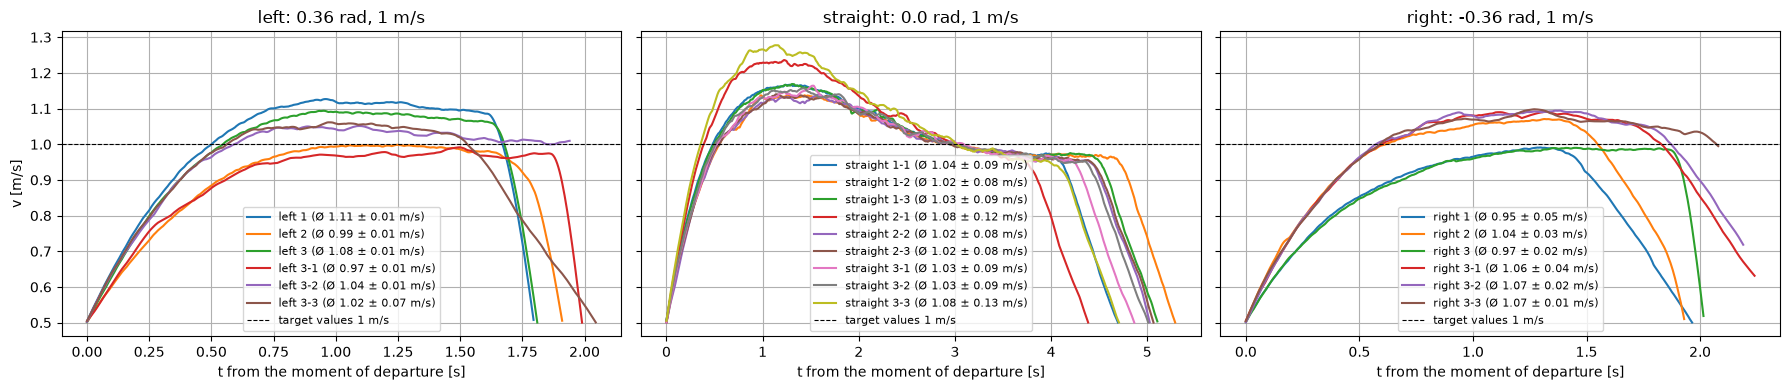

In [ ]:
from scipy.signal import savgol_filter

rate = 200        # Raster in Hz
win_s = 0.3       # Fensterlänge in Sekunden
v_min = 0.5

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run].drop_duplicates(subset="t")
        t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()

        tm = np.arange(t[0], t[-1], 1/rate)
        xu = np.interp(tm, t, x)
        yu = np.interp(tm, t, y)

        win = int(win_s * rate) | 1 # uneven window length for savgol_filter
        vx = savgol_filter(xu, win, polyorder=2, deriv=1, delta=1/rate)
        vy = savgol_filter(yu, win, polyorder=2, deriv=1, delta=1/rate)
        v = np.hypot(vx, vy)

        h = win // 2
        v, tm = v[h:-h], tm[h:-h]

        idx = np.flatnonzero(v > v_min)
        v, tm = v[idx[0]:idx[-1] + 1], tm[idx[0]:idx[-1] + 1] # outliers at the beginning and end are removed but not the ones in between

        steady = (tm - tm[0] > 0.7) & (tm < tm[-1] - 0.3)
        v_mean, v_std = v[steady].mean(), v[steady].std()

        ax.plot(tm - tm[0], v, color=colors[i % len(colors)],
                label=f"{g} {run} (Ø {v_mean:.2f} ± {v_std:.2f} m/s)")

    ax.axhline(1.0, color="k", ls="--", lw=0.8, label="target values 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v [m/s]")
plt.tight_layout()
plt.show()

t (header.stamp): Rate 175.2 Hz | min 3.84  max 26.55  std 1.39 ms
t_log (Aufnahme): Rate 174.9 Hz | min 3.86  max 26.49  std 1.39 ms
Korrelation dt vs dt_log: 0.9978525588468192


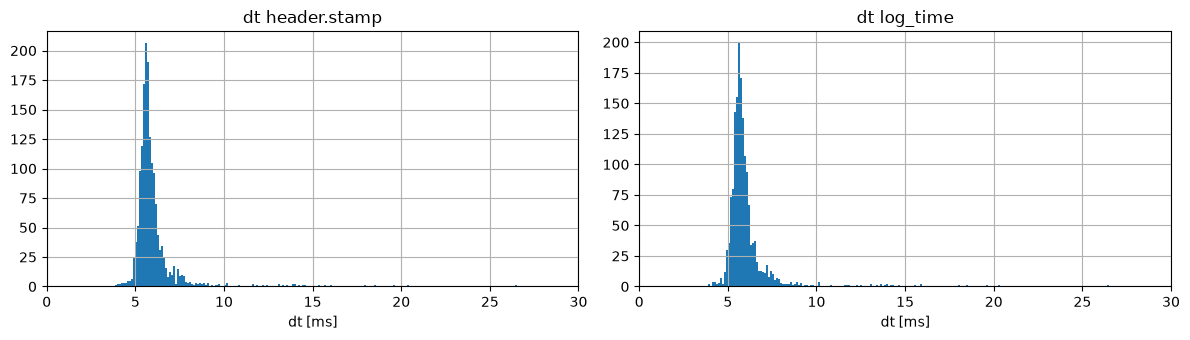

In [36]:
df = dfs["straight"]["1-1"]
dt     = np.diff(df["t"].to_numpy()) * 1e3
dt_log = np.diff(df["t_log"].to_numpy()) * 1e3

for name, d in [("t (header.stamp)", dt), ("t_log (Aufnahme)", dt_log)]:
    print(f"{name}: Rate {1e3/np.median(d):.1f} Hz | "
          f"min {d.min():.2f}  max {d.max():.2f}  std {d.std():.2f} ms")

print("Korrelation dt vs dt_log:", np.corrcoef(dt, dt_log)[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
axes[0].hist(dt, bins=200);     axes[0].set_title("dt header.stamp")
axes[1].hist(dt_log, bins=200); axes[1].set_title("dt log_time")
for ax in axes:
    ax.set_xlabel("dt [ms]"); ax.set_xlim(0, 30); ax.grid(True)
plt.tight_layout(); plt.show()

In [39]:
print((df["t_log"] - df["t"]).describe())

count    1632.000000
mean        0.000185
std         0.000063
min         0.000103
25%         0.000148
50%         0.000165
75%         0.000201
max         0.000787
dtype: float64


### Check on Simulation Datapoints

In [ ]:
with open("data-sim/stage-1-test-left-1/stage-1-test-left-1.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   24
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/move_base_simple/goal                   geometry_msgs/msg/PoseStamped            0
/clicked_point                           geometry_msgs/msg/PointStamped           0
/initialpose                             geometry_msgs/msg/PoseWithCovarianceStamped 0
/tf                                      tf2_msgs/msg/TFMessage                   65
/odom                                    nav_msgs/msg/Odometry                    65
/topic                                   std_msgs/msg/Float32                     65
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 104


stage-1-test-left-3: 127 Msg
stage-1-test-right-2: 45 Msg
stage-1-test-straight-2: 133 Msg
stage-1-test-right-3: 69 Msg
stage-1-test-left-2: 41 Msg
stage-1-test-straight-1: 163 Msg
stage-1-test-straight-2: 169 Msg
stage-1-test-right-1: 74 Msg
stage-1-test-left-1: 65 Msg


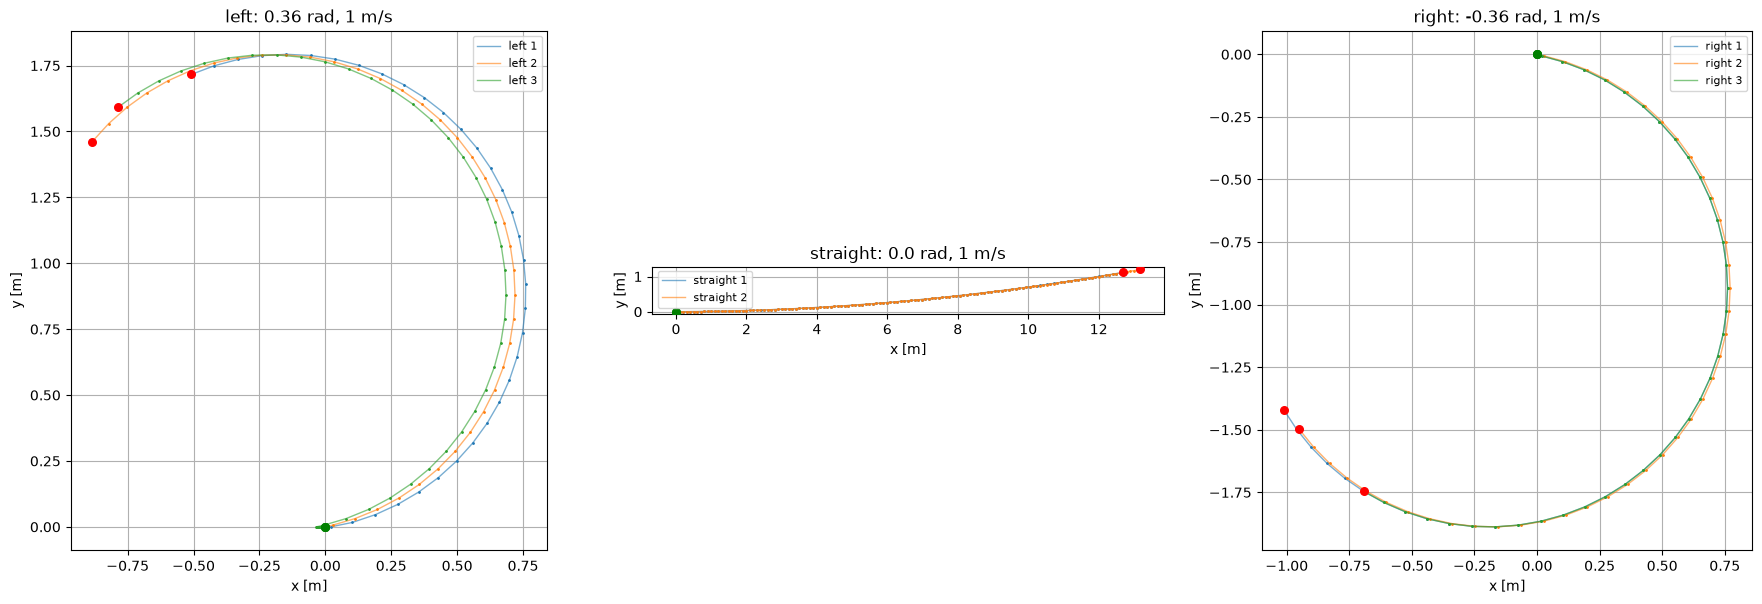

In [ ]:
rootdir = "data-sim/"
n = 1
groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}

def load_sim(path, topic="/odom"):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for schema, channel, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p = msg.pose.pose.position          # Odometry: one level deeper than PoseStamped
            q = msg.pose.pose.orientation
            v = msg.twist.twist.linear
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,  # sim time
                "t_log": message.log_time / 1e9,                               # recording time
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
                "vx": v.x, "vy": v.y,
            })
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return df.sort_values("t").drop_duplicates(subset="t").reset_index(drop=True)

def normalize_start(df):
    # shift so the run starts at (0, 0) and rotate so it starts heading in +x
    x0, y0 = df["px"].iloc[0], df["py"].iloc[0]
    qx, qy, qz, qw = df[["qx", "qy", "qz", "qw"]].iloc[0]
    yaw0 = np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))

    dx, dy = df["px"] - x0, df["py"] - y0
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    df = df.copy()
    df["px"] = c * dx - s * dy
    df["py"] = s * dx + c * dy
    return df

dfs = {g: {} for g in groups}
for subdir, dirs, files in os.walk(rootdir):
    for file in files:
        if not file.endswith(".mcap"):
            continue
        name = os.path.splitext(file)[0]

        m = re.search(r"(left|straight|right)-(\d+)", name)
        if not m:
            continue
        group, run = m.group(1), int(m.group(2))

        df = load_sim(os.path.join(subdir, file))
        if df.empty:
            print(f"{name}: no /odom messages, skipped")
            continue
        print(f"{name}: {len(df)} Msg")
        dfs[group][run] = normalize_start(df)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.tab10.colors

for ax, group in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[group])):
        df = dfs[group][run]
        c = colors[i % len(colors)]
        ax.plot(df["px"], df["py"], "-", color=c, linewidth=1, alpha=0.6, label=f"{group} {run}")
        ax.plot(df["px"][::n], df["py"][::n], "o", color=c, markersize=1)
        ax.scatter(df["px"].iloc[0], df["py"].iloc[0], color="green", s=30, zorder=3)
        ax.scatter(df["px"].iloc[-1], df["py"].iloc[-1], color="red", s=30, zorder=3)

    ax.set_title(titles[group])
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    if dfs[group]:
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

##### Check on Sim Speed

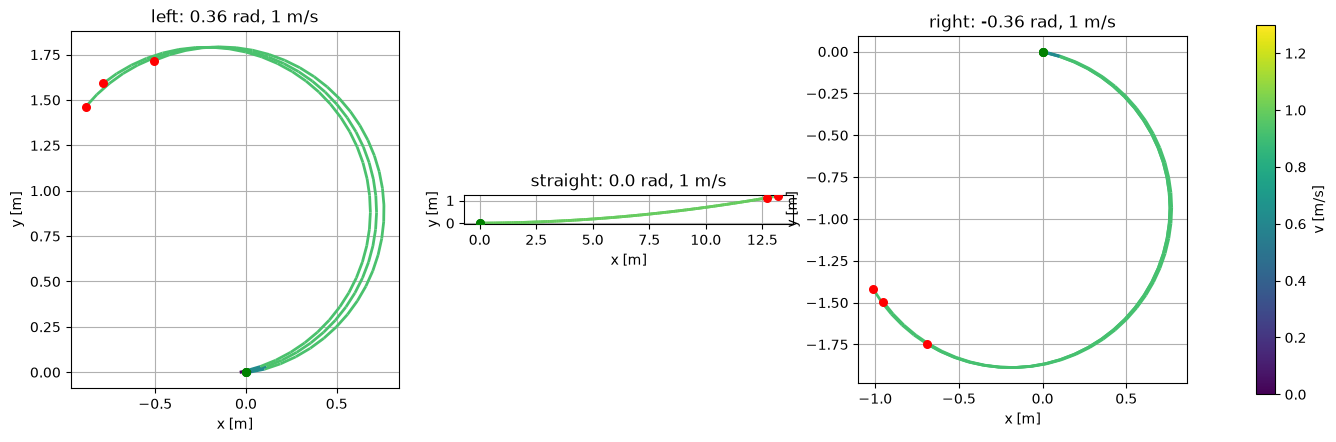

In [ ]:
vmax_plot = 1.3  # upper limit of the color scale [m/s]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
lc = None
for ax, g in zip(axes, groups):
    for run in sorted(dfs[g]):
        df = dfs[g][run]
        x, y = df["px"].to_numpy(), df["py"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry

        segs = np.stack([np.column_stack([x[:-1], y[:-1]]),
                         np.column_stack([x[1:], y[1:]])], axis=1)
        lc = LineCollection(segs, cmap="viridis", norm=plt.Normalize(0, vmax_plot), linewidth=2)
        lc.set_array(v[:-1])
        ax.add_collection(lc)
        ax.scatter(x[0], y[0], color="green", s=30, zorder=3)
        ax.scatter(x[-1], y[-1], color="red", s=30, zorder=3)

    ax.autoscale()
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_aspect("equal"); ax.grid(True)

if lc is not None:
    fig.colorbar(lc, ax=axes, label="v [m/s]", shrink=0.8)
plt.show()

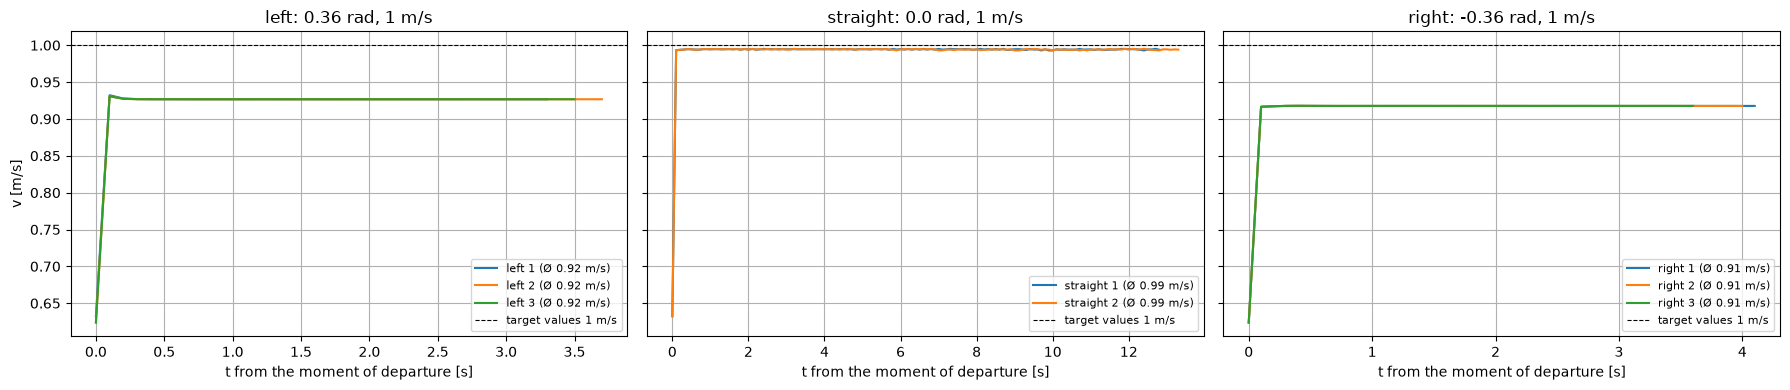

In [ ]:
v_min = 0.5

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run]
        t = df["t"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry

        idx = np.flatnonzero(v > v_min)               # cut standstill at start and end
        if len(idx) == 0:
            print(f"{g} {run}: never faster than {v_min} m/s, skipped")
            continue
        v, t = v[idx[0]:idx[-1] + 1], t[idx[0]:idx[-1] + 1]

        ax.plot(t - t[0], v, color=colors[i % len(colors)],
                label=f"{g} {run} (Ø {v[v > v_min].mean():.2f} m/s)")

    ax.axhline(1.0, color="k", ls="--", lw=0.8, label="target values 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v [m/s]")
plt.tight_layout()
plt.show()

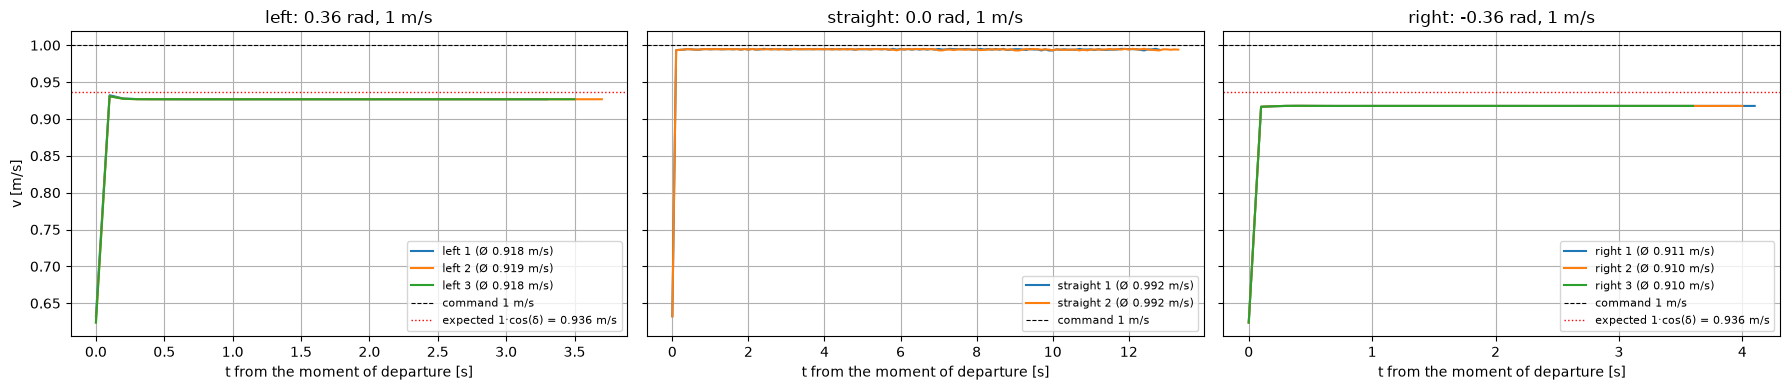

In [ ]:
v_min = 0.5
v_cmd = 1.0                                    # input speed in the simulation
deltas = {"left": 0.36, "straight": 0.0, "right": -0.36}
convert_to_front = False                       # True: speed converted to the front wheel (v / cos δ)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    c = np.cos(deltas[g])

    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run]
        t = df["t"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry
        if convert_to_front:
            v = v / c

        idx = np.flatnonzero(v > v_min)               # cut standstill at start and end
        if len(idx) == 0:
            print(f"{g} {run}: never faster than {v_min} m/s, skipped")
            continue
        v, t = v[idx[0]:idx[-1] + 1], t[idx[0]:idx[-1] + 1]

        ax.plot(t - t[0], v, color=colors[i % len(colors)],
                label=f"{g} {run} (Ø {v[v > v_min].mean():.3f} m/s)")

    ax.axhline(v_cmd, color="k", ls="--", lw=0.8, label=f"command {v_cmd:.0f} m/s")
    if not convert_to_front and deltas[g] != 0:
        ax.axhline(v_cmd * c, color="r", ls=":", lw=1.0,
                   label=f"expected 1·cos(δ) = {v_cmd * c:.3f} m/s")

    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v [m/s]")
plt.tight_layout()
plt.show()

### Check on Sim-Path and Real-Path

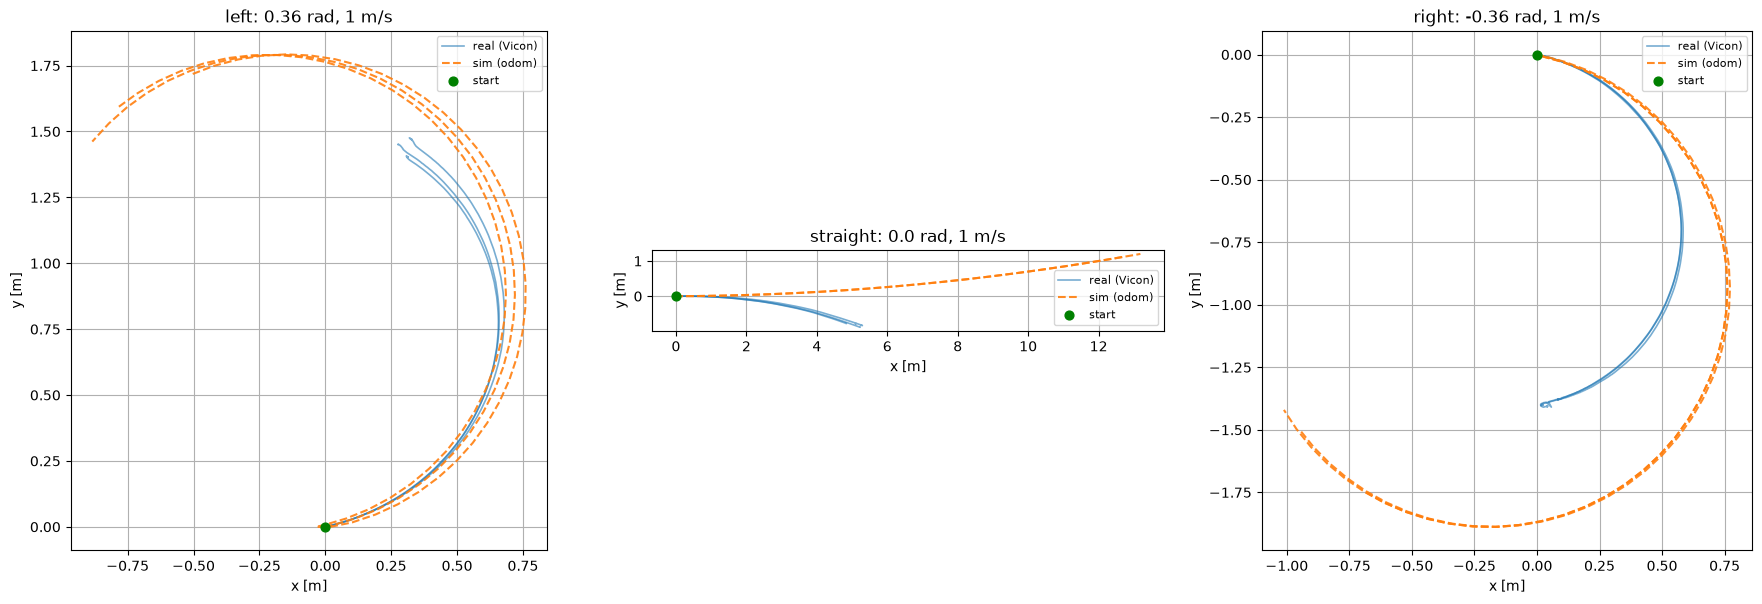

In [ ]:
def load_all(rootdir, loader, clean=None):
    out = {g: {} for g in groups}
    for subdir, dirs, files in os.walk(rootdir):
        for file in files:
            if not file.endswith(".mcap"):
                continue
            name = os.path.splitext(file)[0]
            m = re.search(r"(left|straight|right)-(\d+)", name)
            if not m:
                continue
            group, run = m.group(1), int(m.group(2))

            df = loader(os.path.join(subdir, file))
            if clean is not None:
                df = clean(df)
            if df.empty:
                print(f"{rootdir}{name}: empty, skipped")
                continue
            out[group][run] = normalize_start(df)
    return out

dfs_real = load_all("data-real/", load_vicon, clean=lambda d: remove_jumps(d, max_speed=5.0))
dfs_sim  = load_all("data-sim/",  load_sim)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, groups):
    for j, run in enumerate(sorted(dfs_real[g])):
        df = dfs_real[g][run]
        ax.plot(df["px"], df["py"], "-", color="tab:blue", lw=1.2, alpha=0.6,
                label="real (Vicon)" if j == 0 else None)

    for j, run in enumerate(sorted(dfs_sim[g])):
        df = dfs_sim[g][run]
        ax.plot(df["px"], df["py"], "--", color="tab:orange", lw=1.5, alpha=0.9,
                label="sim (odom)" if j == 0 else None)

    ax.scatter(0, 0, color="green", s=40, zorder=3, label="start")
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Error 